In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/clustering/D4/'

In [2]:
df_cosine = pd.read_csv(main_dir + 'UniqueMappingClustering_cosine.csv')
df_cosine['similarity'] = 'cosine'
df_dice = pd.read_csv(main_dir + 'UniqueMappingClustering_dice.csv')
df_dice['similarity'] = 'dice'
df_jaccard = pd.read_csv(main_dir + 'UniqueMappingClustering_jaccard.csv')
df_jaccard['similarity'] = 'jaccard'
df_scm = pd.read_csv(main_dir + 'UniqueMappingClustering_scm.csv')
df_scm['similarity'] = 'scm'

In [3]:
result = pd.DataFrame()
dfs = [df_cosine, df_dice, df_jaccard, df_scm]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,total_clusters,threshold,matcher,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,Clustering with UniqueMappingClustering,2262,0.20,cosine,96.11,98.19,97.14,2174,88,2594,40,cosine,[title],1024,0,1,salted_qgrams,,4
1,Clustering with UniqueMappingClustering,2254,0.30,cosine,96.45,98.19,97.31,2174,80,2594,40,cosine,[title],1024,0,1,salted_qgrams,,4
2,Clustering with UniqueMappingClustering,2238,0.40,cosine,97.14,98.19,97.66,2174,64,2594,40,cosine,[title],1024,0,1,salted_qgrams,,4
3,Clustering with UniqueMappingClustering,2232,0.50,cosine,97.40,98.19,97.80,2174,58,2594,40,cosine,[title],1024,0,1,salted_qgrams,,4
4,Clustering with UniqueMappingClustering,2219,0.60,cosine,97.79,98.01,97.90,2170,49,2590,44,cosine,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2427,Clustering with UniqueMappingClustering,1,0.55,scm,100.00,0.05,0.09,1,0,421,2213,scm,[title],1024,0,32,salted_qgrams,,4
2428,Clustering with UniqueMappingClustering,3,0.65,scm,33.33,0.05,0.09,1,2,421,2213,scm,[title],1024,0,32,salted_qgrams,,4
2429,Clustering with UniqueMappingClustering,70,0.75,scm,81.43,2.57,4.99,57,13,477,2157,scm,[title],1024,0,32,salted_qgrams,,4
2430,Clustering with UniqueMappingClustering,2200,0.85,scm,97.86,97.24,97.55,2153,47,2573,61,scm,[title],1024,0,32,salted_qgrams,,4


In [4]:
result['attributes'].value_counts()

attributes
[title]    2432
Name: count, dtype: int64

In [5]:
result['offset'].value_counts()

offset
0    2432
Name: count, dtype: int64

In [6]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    2432
Name: count, dtype: int64

In [7]:
result['qgrams'].value_counts()

qgrams
4    2432
Name: count, dtype: int64

In [8]:
result['size'].value_counts()

size
1024    2432
Name: count, dtype: int64

In [9]:
result['num_hashes'].value_counts()

num_hashes
1     76
2     76
3     76
4     76
5     76
6     76
7     76
8     76
9     76
10    76
11    76
12    76
13    76
14    76
15    76
16    76
17    76
18    76
19    76
20    76
21    76
22    76
23    76
24    76
25    76
26    76
27    76
28    76
29    76
30    76
31    76
32    76
Name: count, dtype: int64

In [10]:
max_f1 = result.loc[result.groupby(['num_hashes','similarity'])['F1 %'].idxmax()]
max_f1

,name,total_clusters,threshold,matcher,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
4,Clustering with UniqueMappingClustering,2219,0.60,cosine,97.79,98.01,97.90,2170,49,2590,44,cosine,[title],1024,0,1,salted_qgrams,,4
901,Clustering with UniqueMappingClustering,2220,0.55,dice,97.79,98.06,97.93,2171,49,2591,43,dice,[title],1024,0,1,salted_qgrams,,4
1219,Clustering with UniqueMappingClustering,2217,0.40,jaccard,97.83,97.97,97.90,2169,48,2589,45,jaccard,[title],1024,0,1,salted_qgrams,,4
1830,Clustering with UniqueMappingClustering,2270,0.90,scm,95.73,98.15,96.92,2173,97,2593,41,scm,[title],1024,0,1,salted_qgrams,,4
13,Clustering with UniqueMappingClustering,2220,0.60,cosine,97.79,98.06,97.93,2171,49,2591,43,cosine,[title],1024,0,2,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2094,Clustering with UniqueMappingClustering,2210,0.80,scm,97.65,97.47,97.56,2158,52,2578,56,scm,[title],1024,0,31,salted_qgrams,,4
279,Clustering with UniqueMappingClustering,2194,0.90,cosine,97.77,96.88,97.32,2145,49,2565,69,cosine,[title],1024,0,32,salted_qgrams,,4
887,Clustering with UniqueMappingClustering,2194,0.90,dice,97.77,96.88,97.32,2145,49,2565,69,dice,[title],1024,0,32,salted_qgrams,,4
1496,Clustering with UniqueMappingClustering,2198,0.80,jaccard,97.77,97.06,97.42,2149,49,2569,65,jaccard,[title],1024,0,32,salted_qgrams,,4


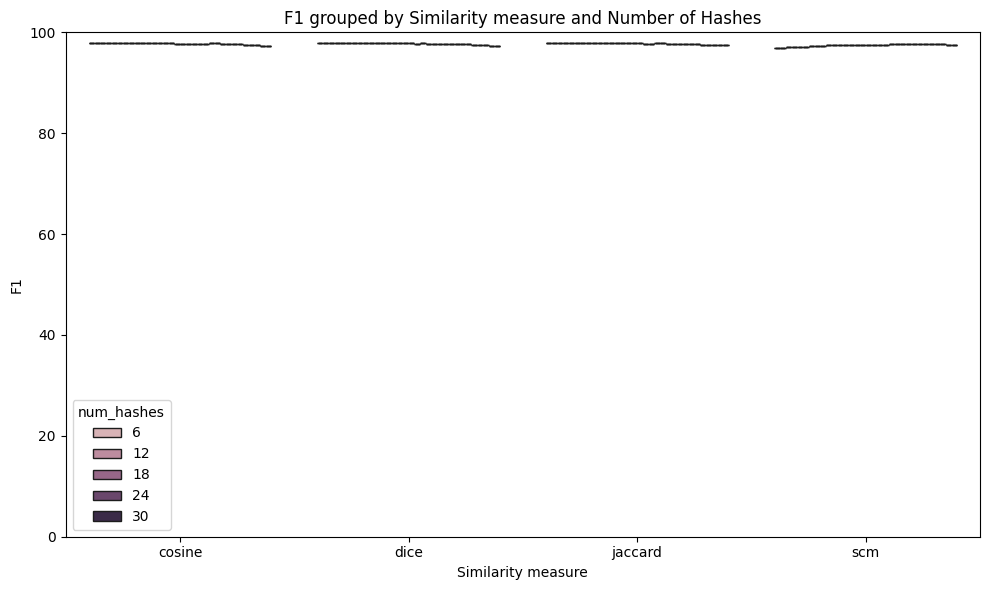

In [11]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=max_f1,
    x="similarity",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by Similarity measure and Number of Hashes")
plt.xlabel("Similarity measure")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [12]:
metrics_df = max_f1.melt(
    id_vars=["similarity", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,similarity,num_hashes,Metric,Score
0,cosine,1,Precision %,97.79
1,dice,1,Precision %,97.79
2,jaccard,1,Precision %,97.83
3,scm,1,Precision %,95.73
4,cosine,2,Precision %,97.79
...,...,...,...,...
379,scm,31,F1 %,97.56
380,cosine,32,F1 %,97.32
381,dice,32,F1 %,97.32
382,jaccard,32,F1 %,97.42


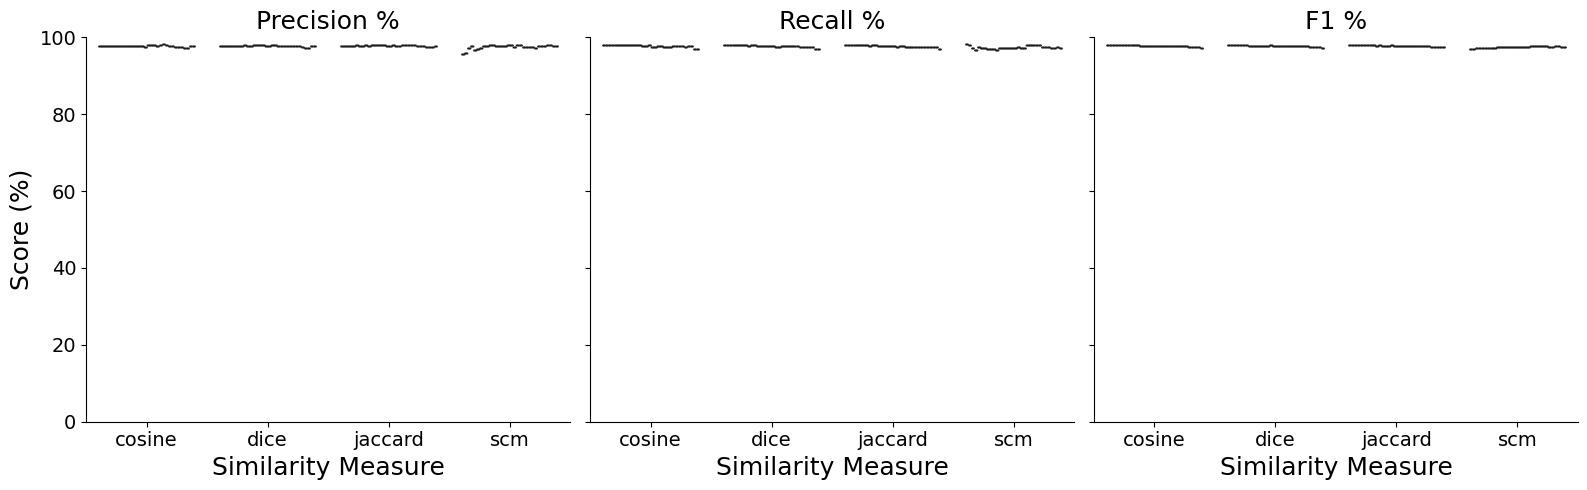

In [13]:
g = sns.catplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("Similarity Measure", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

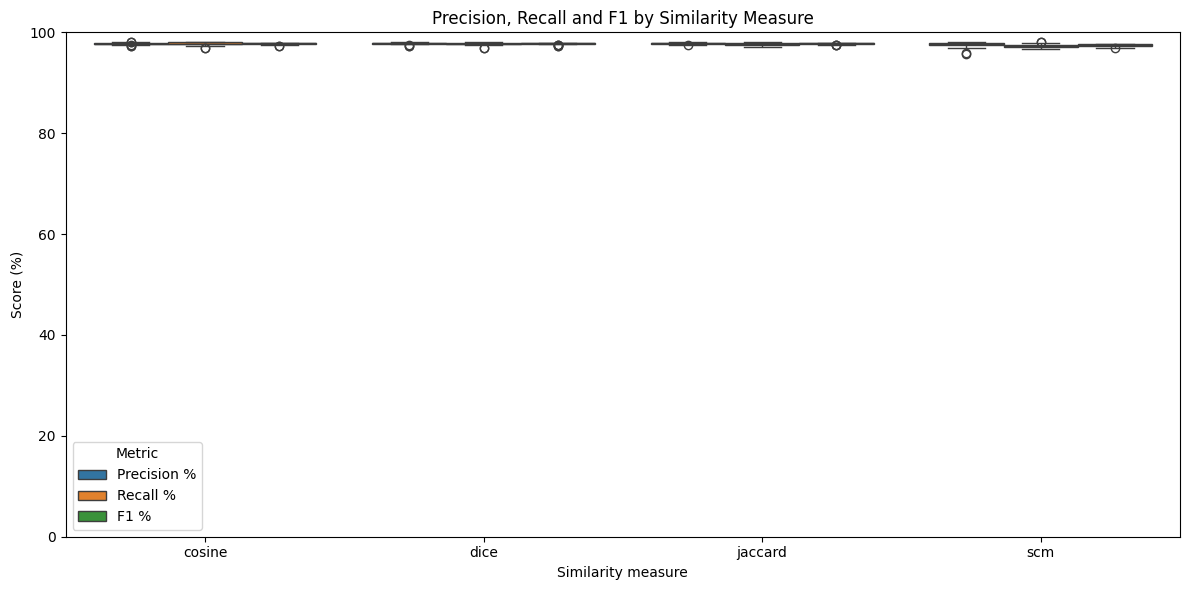

In [14]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by Similarity Measure")
plt.xlabel("Similarity measure")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()